## **X8**: TT - Training the Ansatz Parameters θ with the MLP
* October 11°, 2026
#### ESCOM - IPN:

#### *B.S. in Computer Science*
> Miguel Alexander Sanchez Garcia

#### **0° Introduction**

Architecture B fixes θ and never trains it (D-014). X7 showed that the draw of θ moves the AUC of C4 and C5 by up to 0.11, and X4 showed that the C4 kernel read by an SVM loses much less than the MLP reading 12 values ⟨Zᵢ⟩: the loss is in the readout. This notebook asks the question that both results leave open: **if θ is trained together with the MLP, how much of the gap to the classical conditions closes?** It is an exploratory, post hoc analysis in the sense of D-038; the design of the thesis stays Architecture B.

**What θ is.** The state is $|\psi(\mathbf{x})\rangle = V(\theta)\,U_\Phi(\mathbf{x})\,|0\rangle^{\otimes 12}$ and the MLP reads $\langle Z_i\rangle = \mathrm{Tr}\big(\rho(\mathbf{x})\,V(\theta)^\dagger Z_i V(\theta)\big)$ with $\rho(\mathbf{x}) = U_\Phi|0\rangle\langle 0|U_\Phi^\dagger$. Each output is a **linear functional of the encoded state**; θ chooses which 12 functionals are read. Training θ learns them, as training the first layer of a network instead of leaving it random. The fidelity kernel does not depend on θ ($V^\dagger V = I$), so Module 6 and X4 are unchanged.

**How the gradient is computed, and why this matters for the design.**

| Method | What it needs | Cost per lesion, k = 12 | Possible on hardware |
|---|---|---|---|
| Parameter shift (H-011, H-051) | Two circuit evaluations per parameter: 48 for the 24 parameters | measured in 2° | yes |
| Automatic differentiation through the state vector | The 4,096 amplitudes of the state, kept in memory | measured in 2° | **no** |

The parameter-shift rule is a property of the formalism: for a gate $e^{-i\theta P/2}$ with a Pauli generator, $\partial_\theta\langle O\rangle = \tfrac12\big[\langle O\rangle_{\theta+\pi/2} - \langle O\rangle_{\theta-\pi/2}\big]$ exactly, from measurements alone. Automatic differentiation is a property of the **simulator**: it back-propagates through the stored amplitudes, which a quantum computer never exposes, because measuring collapses the state. It is the same kind of shortcut as the state-vector kernel of H-032. Both give the same exact gradient; 2° checks it.

**Protocol.** Module 7 with one change: θ is a trainable parameter.

| Element | Choice, fixed before any result |
|---|---|
| Circuits | `zz_feature_map` (C4) and `pauli_feature_map(['Y','ZZ'])` (C5), reps = 1, then `real_amplitudes(12, reps=1)`; 24 parameters |
| Initial θ | The design draw (seed 42, D-014) |
| Network and training | Module 7, D-036: k → 32 → 16 → 1, Adam, batches of 128, weighted BCE, early stopping with patience 40 on 15 % of the training patients, at most 400 epochs, seed 42 |
| Learning rates | 10⁻³ and weight decay 10⁻⁴ for the MLP, as in Module 7; **10⁻² and no weight decay for θ**, because θ are angles of order 1 and a periodic parameter has no natural decay toward 0 |
| Standardization of ⟨Zᵢ⟩ | Mean and standard deviation of the embedding at the initial θ on the training part, then fixed |
| Evaluation | Folds of Module 4; the official test **once per subset and map**, only for the main configuration |
| Sensitivity, cross-validation only | Initial θ from seeds 43 and 44 (two draws of X7), and learning rate 10⁻³ for θ |
| Check | With θ frozen, the same code must reproduce the fold AUCs of Module 7 |

#### **1° Setup**

**a.** Libraries, parameters and data

In [1]:
import copy
import json
import os
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qiskit
import qiskit_machine_learning
import torch
from joblib import Parallel, delayed
from qiskit.circuit.library import pauli_feature_map, real_amplitudes, zz_feature_map
from qiskit.primitives import StatevectorEstimator
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit_machine_learning.neural_networks import EstimatorQNN
from scipy.stats import rankdata
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GroupShuffleSplit

warnings.filterwarnings('ignore')
torch.use_deterministic_algorithms(True)
torch.set_num_threads(1)
SEED, N_QUBITS = 42, 12
FINDINGS = ['mass', 'calcification']
TITLES = {'mass': 'Masses', 'calcification': 'Calcifications'}
QUANTUM = ['C4', 'C5']
N_FOLDS, BATCH, MAX_EPOCHS, PATIENCE, INNER_VAL = 5, 128, 400, 40, 0.15
HIDDEN, LR, WEIGHT_DECAY = (32, 16), 1e-3, 1e-4          # Module 7, D-036
LR_THETA = 1e-2                                           # fixed before any result
CONFIGS = {'main': dict(theta_seed=42, lr_theta=LR_THETA),
           'frozen': dict(theta_seed=42, lr_theta=0.0),
           'theta0 seed 43': dict(theta_seed=43, lr_theta=LR_THETA),
           'theta0 seed 44': dict(theta_seed=44, lr_theta=LR_THETA),
           'lr theta 1e-3': dict(theta_seed=42, lr_theta=1e-3)}
N_JOBS, N_BOOT = 6, 2000
PROGRESS = Path('/tmp/x8_progress.log')
ROOT = Path('/Users/alexander_san/TT')
M5_DIR, M7_DIR = ROOT / 'Data/processed/m5', ROOT / 'Data/processed/m7'
RESULTS_DIR, FIG_DIR = ROOT / 'Code/results', ROOT / 'Docs/Figures'
COLORS = {'C1': '#eda100', 'C4': '#eb6834', 'C5': '#1baf7a'}
INK, MUTED = '#3d3d3a', '#8a8a85'
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.25, 'lines.linewidth': 2, 'lines.markersize': 8})

checks = []


def check(name, value, passed):
    checks.append({'check': name, 'value': float(value), 'passed': bool(passed)})


cols = lambda c: [f'{c}_{j:02d}' for j in range(1, 13)]
frames = {ft: pd.read_parquet(M5_DIR / f'emb_{ft}.parquet') for ft in FINDINGS}
ansatz = real_amplitudes(N_QUBITS, reps=1)
theta_draw = lambda s: np.random.default_rng(s).uniform(0, 2 * np.pi, ansatz.num_parameters)
theta_design = np.array(json.loads((M5_DIR / 'emb_meta.json').read_text())['theta'])
check('theta seed 42 reproduces the theta of Module 5', np.abs(theta_draw(42) - theta_design).max(), np.array_equal(theta_draw(42), theta_design))
m7_cv = pd.read_csv(RESULTS_DIR / '7_cv_por_fold.csv')
m7_pred = pd.read_parquet(M7_DIR / 'predicciones.parquet')
x4_test = pd.read_csv(RESULTS_DIR / 'X4_test.csv')
print(f'qiskit {qiskit.__version__} | qiskit-machine-learning {qiskit_machine_learning.__version__} | torch {torch.__version__} (CPU, deterministic) | {os.cpu_count()} CPUs, {N_JOBS} workers')
for ft, f in frames.items():
    print(f'{ft:13s}: {int((f.split == "train").sum())} train and {int((f.split == "test").sum())} test lesions')

qiskit 2.3.0 | qiskit-machine-learning 0.9.0 | torch 2.10.0 (CPU, deterministic) | 8 CPUs, 6 workers
mass         : 1318 train and 378 test lesions
calcification: 1546 train and 326 test lesions


#### **2° The circuit as a differentiable layer**

**a.** The ansatz is read gate by gate from the circuit that Qiskit builds, and applied to a batch of states as a tensor of shape (lesions, 2, …, 2). Qiskit orders amplitudes little-endian, so qubit $q$ is axis $1 + (11 - q)$. The feature-map states $U_\Phi(\mathbf{x})|0\rangle$ do not depend on θ and are computed once with Qiskit. The layer must reproduce the embeddings of Module 5 for every lesion.

In [2]:
gates, pindex = [], {p: i for i, p in enumerate(ansatz.parameters)}
for inst in ansatz.data:
    q = [ansatz.find_bit(b).index for b in inst.qubits]
    if inst.operation.name == 'ry':
        gates.append(('ry', q[0], pindex[inst.operation.params[0]]))
    elif inst.operation.name == 'cx':
        gates.append(('cx', q[0], q[1]))
    else:
        raise ValueError(f'unexpected gate {inst.operation.name}')
signs = torch.tensor(1.0 - 2.0 * ((np.arange(2 ** N_QUBITS)[:, None] >> np.arange(N_QUBITS)) & 1), dtype=torch.float64)


def axis(q):
    return 1 + (N_QUBITS - 1 - q)


def apply_ansatz(psi, theta):
    # V(theta) on a batch of states: RY rotations and CX permutations on the tensor axes
    psi = psi.reshape((-1,) + (2,) * N_QUBITS)
    for op in gates:
        if op[0] == 'ry':
            _, q, i = op
            c, s = torch.cos(theta[i] / 2), torch.sin(theta[i] / 2)
            a0, a1 = psi.select(axis(q), 0), psi.select(axis(q), 1)
            psi = torch.stack([c * a0 - s * a1, s * a0 + c * a1], dim=axis(q))
        else:
            _, ctl, tgt = op
            a0, a1 = psi.select(axis(ctl), 0), psi.select(axis(ctl), 1)
            ta = axis(tgt) - (1 if axis(tgt) > axis(ctl) else 0)
            psi = torch.stack([a0, a1.flip(ta)], dim=axis(ctl))
    return psi.reshape(-1, 2 ** N_QUBITS)


def readout(psi):
    # <Z_i> = P(bit i = 0) - P(bit i = 1), from the exact probabilities
    return (psi.abs() ** 2) @ signs


feature_maps = {'C4': zz_feature_map(N_QUBITS, reps=1), 'C5': pauli_feature_map(N_QUBITS, reps=1, paulis=['Y', 'ZZ'])}
phis = {}
t0 = time.perf_counter()
for ft, f in frames.items():
    x = f[cols('C1')].to_numpy(float)                      # C1 is the angle vector of Module 4
    for q, fm in feature_maps.items():
        phis[(ft, q)] = np.stack([Statevector(fm.assign_parameters(dict(zip(fm.parameters, row)))).data for row in x])
        with torch.no_grad():
            z = readout(apply_ansatz(torch.from_numpy(phis[(ft, q)]), torch.tensor(theta_design))).numpy()
        err = np.abs(z - f[cols(q)].to_numpy()).max()
        check(f'{ft}: {q} through the torch layer equals the embedding of Module 5 (all lesions)', err, err <= 1e-12)
print(f'{sum(len(v) for v in phis.values())} feature-map states in {time.perf_counter() - t0:.0f} s')
display(pd.DataFrame(checks))

7136 feature-map states in 61 s


,check,value,passed
0,theta seed 42 reproduces the theta of Module 5,0.000000e+00,True
1,mass: C4 through the torch layer equals the em...,4.218847e-15,True
2,mass: C5 through the torch layer equals the em...,6.328271e-15,True
3,calcification: C4 through the torch layer equa...,3.941292e-15,True
4,calcification: C5 through the torch layer equa...,5.773160e-15,True


**b.** The same gradient by two methods. `EstimatorQNN` computes the Jacobian of the 12 outputs with respect to the 24 parameters by parameter shift, with exact expectation values (`default_precision=0.0`, H-019); automatic differentiation computes it through the stored amplitudes. On 20 mass lesions with C4 the two Jacobians must agree, and their costs are measured. Training needs the gradient of a scalar loss, which automatic differentiation obtains with one backward pass for all parameters, while parameter shift still needs all the shifted circuits.

In [3]:
obs = [SparsePauliOp.from_sparse_list([('Z', [i], 1.0)], num_qubits=N_QUBITS) for i in range(N_QUBITS)]
fm = feature_maps['C4']
qnn = EstimatorQNN(circuit=fm.compose(ansatz), estimator=StatevectorEstimator(), observables=obs,
                   input_params=list(fm.parameters), weight_params=list(ansatz.parameters), default_precision=0.0)
x20 = frames['mass'][cols('C1')].to_numpy(float)[:20]
phi20 = torch.from_numpy(phis[('mass', 'C4')][:20])
qnn.forward(x20[:1], theta_design)                                  # warm-up, excluded
t0 = time.perf_counter(); fwd_ps = qnn.forward(x20, theta_design); t_fwd_ps = (time.perf_counter() - t0) / 20
t0 = time.perf_counter(); _, jac_ps = qnn.backward(x20, theta_design); t_ps = (time.perf_counter() - t0) / 20

th = torch.tensor(theta_design, requires_grad=True)
t0 = time.perf_counter()
jac_ad = torch.autograd.functional.jacobian(lambda t: readout(apply_ansatz(phi20, t)), th).numpy()
t_jac_ad = (time.perf_counter() - t0) / 20
t0 = time.perf_counter()
readout(apply_ansatz(phi20, th)).sum().backward()
t_grad_ad = (time.perf_counter() - t0) / 20
with torch.no_grad():
    fwd_ad = readout(apply_ansatz(phi20, th)).numpy()
check('parameter shift and the torch layer give the same <Z_i> (20 lesions)', np.abs(fwd_ps - fwd_ad).max(), np.abs(fwd_ps - fwd_ad).max() <= 1e-10)
check('parameter shift and automatic differentiation give the same Jacobian (20 x 12 x 24)', np.abs(jac_ps - jac_ad).max(), np.abs(jac_ps - jac_ad).max() <= 1e-8)

n_train = sum(int((f.split == 'train').sum()) for f in frames.values())
cost = pd.DataFrame([
    {'method': 'parameter shift (EstimatorQNN, exact)', 'gradient': 'Jacobian 12 x 24 (also needed for a scalar loss)', 'seconds_per_lesion': t_ps},
    {'method': 'automatic differentiation (state vector)', 'gradient': 'Jacobian 12 x 24', 'seconds_per_lesion': t_jac_ad},
    {'method': 'automatic differentiation (state vector)', 'gradient': 'scalar loss, one backward pass', 'seconds_per_lesion': t_grad_ad}])
cost['hours_50_epochs_one_map_all_train'] = cost.seconds_per_lesion * n_train * 50 / 3600
cost['forward_seconds_per_lesion_parameter_shift_primitive'] = t_fwd_ps
cost.to_csv(RESULTS_DIR / 'X8_costo_gradiente.csv', index=False)
display(cost)
print(f'max |Jacobian difference| = {np.abs(jac_ps - jac_ad).max():.2e}; parameter shift is {t_ps / t_grad_ad:,.0f} times slower than one backward pass')

No gradient function provided, creating a gradient function. If your Estimator requires transpilation, please provide a pass manager.


,method,gradient,seconds_per_lesion,hours_50_epochs_one_map_all_train,forward_seconds_per_lesion_parameter_shift_primitive
0,"parameter shift (EstimatorQNN, exact)",Jacobian 12 x 24 (also needed for a scalar loss),5.158940,205.211166,0.093688
1,automatic differentiation (state vector),Jacobian 12 x 24,0.236929,9.424523,0.093688
2,automatic differentiation (state vector),"scalar loss, one backward pass",0.001420,0.056499,0.093688


max |Jacobian difference| = 1.78e-15; parameter shift is 3,632 times slower than one backward pass


#### **3° Training θ with the MLP**

**a.** One fit: the inner patient split, the class weights and the batch order are those of Module 7, and the MLP is initialized with the same seed, so with θ frozen the fit is the one of Module 7. The best epoch restores both the network and θ.

In [4]:
class MLP(torch.nn.Module):
    def __init__(self, n_in, hidden):
        super().__init__()
        layers, d = [], n_in
        for h in hidden:
            layers += [torch.nn.Linear(d, h), torch.nn.ReLU()]
            d = h
        layers.append(torch.nn.Linear(d, 1))
        self.net = torch.nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)


def class_weights(y):
    n, n1 = len(y), int(y.sum())
    return {0: n / (2 * (n - n1)), 1: n / (2 * n1)}


def fit_trainable(phi, idx_fit, idx_eval, y_fit, groups, theta0, lr_theta, seed, tag):
    torch.use_deterministic_algorithms(True)
    torch.set_num_threads(1)
    start = time.perf_counter()
    inner_tr, inner_va = next(GroupShuffleSplit(n_splits=1, test_size=INNER_VAL, random_state=seed)
                              .split(np.zeros((len(y_fit), 1)), y_fit, groups))
    phi_tr = torch.from_numpy(np.ascontiguousarray(phi[idx_fit[inner_tr]]))
    phi_va = torch.from_numpy(np.ascontiguousarray(phi[idx_fit[inner_va]]))
    phi_ev = torch.from_numpy(np.ascontiguousarray(phi[idx_eval]))
    t_init = torch.tensor(theta0, dtype=torch.float64)
    with torch.no_grad():
        z0 = readout(apply_ansatz(phi_tr, t_init))
    mu, sd = z0.mean(0), z0.std(0, unbiased=False)
    w = class_weights(y_fit[inner_tr])
    yt = torch.tensor(y_fit[inner_tr], dtype=torch.float32)
    wt = torch.where(yt == 1, w[1], w[0])
    yv = torch.tensor(y_fit[inner_va], dtype=torch.float32)
    wv = torch.where(yv == 1, w[1], w[0])
    torch.manual_seed(seed)
    model = MLP(N_QUBITS, HIDDEN)
    theta = torch.nn.Parameter(t_init.clone(), requires_grad=lr_theta > 0)
    if lr_theta > 0:
        opt = torch.optim.Adam([{'params': model.parameters(), 'lr': LR, 'weight_decay': WEIGHT_DECAY},
                                {'params': [theta], 'lr': lr_theta, 'weight_decay': 0.0}])
    else:
        opt = torch.optim.Adam(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    loss_fn = torch.nn.BCEWithLogitsLoss(reduction='none')
    gen = torch.Generator().manual_seed(seed)
    logit = lambda p: model(((readout(apply_ansatz(p, theta)) - mu) / sd).float())
    best, best_state, best_theta, best_epoch, wait = np.inf, None, None, 0, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        order = torch.randperm(len(yt), generator=gen)
        for i in range(0, len(yt), BATCH):
            b = order[i:i + BATCH]
            opt.zero_grad()
            (loss_fn(logit(phi_tr[b]), yt[b]) * wt[b]).mean().backward()
            opt.step()
        model.eval()
        with torch.no_grad():
            val = float((loss_fn(logit(phi_va), yv) * wv).mean())
        if val < best - 1e-6:
            best, best_state, best_theta, best_epoch, wait = val, copy.deepcopy(model.state_dict()), theta.detach().clone(), epoch, 0
        else:
            wait += 1
            if wait >= PATIENCE:
                break
    model.load_state_dict(best_state)
    model.eval()
    with torch.no_grad():
        theta.copy_(best_theta)
        p = torch.sigmoid(logit(phi_ev)).numpy()
    with open(PROGRESS, 'a') as fh:
        fh.write(f'{time.strftime("%H:%M:%S")} {tag} epoch={best_epoch} {time.perf_counter() - start:.0f}s\n')
    return {'prob': p, 'epochs': best_epoch, 'theta': best_theta.numpy(), 'seconds': time.perf_counter() - start}


def metrics(y, p):
    yhat = (p >= 0.5).astype(int)
    return {'auc': roc_auc_score(y, p), 'f1': f1_score(y, yhat, zero_division=0), 'accuracy': accuracy_score(y, yhat),
            'precision': precision_score(y, yhat, zero_division=0), 'recall': recall_score(y, yhat, zero_division=0)}


print('Defined: MLP, class_weights, fit_trainable (theta and MLP, early stopping on an inner patient split), metrics')

Defined: MLP, class_weights, fit_trainable (theta and MLP, early stopping on an inner patient split), metrics


**b.** All fits, in parallel worker processes. Each fit is single-threaded and seeded, so the result does not depend on the worker that runs it.

| Configuration | Subsets and maps | Folds | Test |
|---|---|---|---|
| main | both × C4, C5 | 5 | once |
| frozen (check) | masses × C4 | 5 | no |
| θ₀ seed 43, θ₀ seed 44, lr θ 10⁻³ | both × C4, C5 | 5 | no |

In [5]:
jobs = []
for ft in FINDINGS:
    f = frames[ft]
    tr_idx, te_idx = np.flatnonzero(f.split.eq('train').to_numpy()), np.flatnonzero(f.split.eq('test').to_numpy())
    y_tr, folds, groups = f.label.to_numpy(int)[tr_idx], f.fold.to_numpy(int)[tr_idx], f.patient_id.to_numpy()[tr_idx]
    for q in QUANTUM:
        for name, cfg in CONFIGS.items():
            if name == 'frozen' and (ft, q) != ('mass', 'C4'):
                continue
            theta0 = theta_draw(cfg['theta_seed'])
            for fold in ([-1] if name == 'main' else []) + list(range(N_FOLDS)):
                fit = tr_idx if fold == -1 else tr_idx[folds != fold]
                ev = te_idx if fold == -1 else tr_idx[folds == fold]
                fit_mask = np.ones(len(tr_idx), bool) if fold == -1 else folds != fold
                jobs.append({'finding_type': ft, 'condition': q, 'config': name, 'fold': fold, 'fit': fit, 'eval': ev,
                             'y_fit': y_tr[fit_mask], 'groups': groups[fit_mask], 'theta0': theta0, 'lr_theta': cfg['lr_theta']})
jobs.sort(key=lambda j: (j['fold'] != -1, j['finding_type'] != 'calcification'))      # the longest fits first
PROGRESS.write_text('')
print(f'{len(jobs)} fits on {N_JOBS} workers')
t0 = time.perf_counter()
out = Parallel(n_jobs=N_JOBS, backend='loky')(
    delayed(fit_trainable)(phis[(j['finding_type'], j['condition'])], j['fit'], j['eval'], j['y_fit'], j['groups'],
                           j['theta0'], j['lr_theta'], SEED, f"{j['finding_type']} {j['condition']} {j['config']} fold {j['fold']}")
    for j in jobs)
print(f'done in {(time.perf_counter() - t0) / 60:.0f} min')

89 fits on 6 workers


done in 155 min


#### **4° Results**

**a.** Cross-validation: every configuration next to Module 7 (θ fixed) and C1, and the frozen check

In [6]:
rows = []
for j, o in zip(jobs, out):
    if j['fold'] == -1:
        continue
    f = frames[j['finding_type']]
    y = f.label.to_numpy(int)[j['eval']]
    rows.append({'finding_type': j['finding_type'], 'condition': j['condition'], 'config': j['config'], 'fold': j['fold'],
                 'epochs': o['epochs'], 'seconds': o['seconds'], 'theta_shift': float(np.abs(o['theta'] - j['theta0']).mean()),
                 **metrics(y, o['prob'])})
cv = pd.DataFrame(rows)
main7 = m7_cv[(m7_cv.analysis == 'main') & (m7_cv.seed == SEED)]
frozen = cv[cv.config == 'frozen'].sort_values('fold').auc.to_numpy()
ref = main7[(main7.finding_type == 'mass') & (main7.condition == 'C4')].sort_values('fold').auc.to_numpy()
check('theta frozen reproduces the fold AUCs of Module 7 (masses, C4)', np.abs(frozen - ref).max(), np.abs(frozen - ref).max() <= 0.005)

table = cv.groupby(['finding_type', 'condition', 'config']).auc.mean().unstack('config')
table['Module 7 (theta fixed)'] = main7.groupby(['finding_type', 'condition']).auc.mean()
c1 = main7[main7.condition == 'C1'].groupby('finding_type').auc.mean()
table['C1 (Module 7)'] = [c1[ft] for ft, _ in table.index]
table['main - Module 7'] = table['main'] - table['Module 7 (theta fixed)']
table['C1 - main'] = table['C1 (Module 7)'] - table['main']
display(table.round(3))
display(cv.groupby(['finding_type', 'condition', 'config'])[['epochs', 'seconds', 'theta_shift']].mean().round(2))

config                   frozen  lr theta 1e-3   main  theta0 seed 43  \
finding_type  condition                                                 
calcification C4            NaN          0.670  0.694           0.686   
              C5            NaN          0.671  0.687           0.670   
mass          C4          0.565          0.565  0.568           0.566   
              C5            NaN          0.589  0.612           0.579   

config                   theta0 seed 44  Module 7 (theta fixed)  \
finding_type  condition                                           
calcification C4                  0.660                   0.640   
              C5                  0.663                   0.667   
mass          C4                  0.595                   0.565   
              C5                  0.612                   0.563   

config                   C1 (Module 7)  main - Module 7  C1 - main  
finding_type  condition                                             
calcification C4                 0.742            0.054      0.048  
              C5                 0.742            0.020      0.055  
mass          C4                 0.652            0.003      0.084  
              C5                 0.652            0.048      0.041

epochs  seconds  theta_shift
finding_type  condition config                                      
calcification C4        lr theta 1e-3     23.8   773.89         0.07
                        main              13.2   784.76         0.26
                        theta0 seed 43    29.4   919.38         0.34
                        theta0 seed 44    24.0   807.23         0.32
              C5        lr theta 1e-3     22.2   682.13         0.07
                        main              17.0   676.61         0.31
                        theta0 seed 43    35.4   867.98         0.34
                        theta0 seed 44    40.4   899.62         0.43
mass          C4        frozen             6.0   144.84         0.00
                        lr theta 1e-3      4.6   410.32         0.01
                        main               4.4   403.18         0.10
                        theta0 seed 43    14.8   504.86         0.15
                        theta0 seed 44    11.0   467.12         0.18
              C5        lr theta 1e-3     21.8   466.47         0.05
                        main              12.4   480.71         0.21
                        theta0 seed 43    18.2   534.41         0.22
                        theta0 seed 44    11.8   477.20         0.20

**b.** The official test, once per subset and map. The bootstrap resamples patients with the same resamples as Module 7, so the differences against C1 and against θ fixed are paired.

In [7]:
def fast_auc(y, p):
    r = rankdata(p)
    n1 = y.sum()
    return (r[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * (len(y) - n1))


def patient_bootstrap(test_frame, n_boot, seed):
    patients = test_frame.patient_id.to_numpy()
    uniq, inv = np.unique(patients, return_inverse=True)
    members = [np.flatnonzero(inv == i) for i in range(len(uniq))]
    rng = np.random.default_rng(seed)
    return [np.concatenate([members[i] for i in rng.integers(0, len(uniq), len(uniq))]) for _ in range(n_boot)]


test_rows, diff_rows, thetas = [], [], []
for ft in FINDINGS:
    te7 = m7_pred[(m7_pred.finding_type == ft) & (m7_pred.split == 'test') & (m7_pred.analysis == 'main')]
    ref = te7[te7.condition == 'C1'].reset_index(drop=True)
    samples = patient_bootstrap(ref, N_BOOT, SEED)
    y = ref.label.to_numpy(int)
    dists = {}
    for cond in ['C1', 'C4', 'C5']:
        p7 = te7[te7.condition == cond].set_index('case_id').loc[ref.case_id].prob.to_numpy()
        dists[f'{cond} theta fixed' if cond != 'C1' else 'C1'] = (p7, np.array([fast_auc(y[s], p7[s]) for s in samples]))
    f = frames[ft]
    for j, o in zip(jobs, out):
        if j['finding_type'] != ft or j['fold'] != -1:
            continue
        p = pd.Series(o['prob'], index=f.case_id.to_numpy()[j['eval']]).loc[ref.case_id].to_numpy()
        dists[f"{j['condition']} theta trained"] = (p, np.array([fast_auc(y[s], p[s]) for s in samples]))
        tr = f.split.eq('train').to_numpy()
        with torch.no_grad():
            z = readout(apply_ansatz(torch.from_numpy(phis[(ft, j['condition'])][tr]), torch.tensor(o['theta']))).numpy()
        thetas.append({'finding_type': ft, 'condition': j['condition'], 'epochs': o['epochs'],
                       'mean_abs_change_rad': float(np.abs(o['theta'] - j['theta0']).mean()),
                       'dispersion_theta_fixed': f.loc[tr, cols(j['condition'])].to_numpy().std(0, ddof=1).mean(),
                       'dispersion_theta_trained': z.std(0, ddof=1).mean(),
                       **{f'theta_{i:02d}': v for i, v in enumerate(o['theta'])}})
    for name, (p, dist) in dists.items():
        test_rows.append({'finding_type': ft, 'model': name, **metrics(y, p),
                          'auc_ci_low': np.percentile(dist, 2.5), 'auc_ci_high': np.percentile(dist, 97.5)})
    for a, b in [('C4 theta trained', 'C1'), ('C5 theta trained', 'C1'), ('C4 theta trained', 'C4 theta fixed'), ('C5 theta trained', 'C5 theta fixed')]:
        d = dists[a][1] - dists[b][1]
        diff_rows.append({'finding_type': ft, 'comparison': f'{a} - {b}', 'mean_difference': d.mean(),
                          'ci_low': np.percentile(d, 2.5), 'ci_high': np.percentile(d, 97.5), 'share_above_0': (d > 0).mean()})
test = pd.DataFrame(test_rows)
diffs = pd.DataFrame(diff_rows)
theta_table = pd.DataFrame(thetas)
display(test.round(3))
display(diffs.round(3))
display(theta_table[['finding_type', 'condition', 'epochs', 'mean_abs_change_rad', 'dispersion_theta_fixed', 'dispersion_theta_trained']].round(3))

,finding_type,model,auc,f1,accuracy,precision,recall,auc_ci_low,auc_ci_high
0,mass,C1,0.651,0.519,0.638,0.536,0.503,0.578,0.724
1,mass,C4 theta fixed,0.530,0.386,0.529,0.392,0.381,0.473,0.587
2,mass,C5 theta fixed,0.581,0.456,0.571,0.450,0.463,0.521,0.644
3,mass,C4 theta trained,0.533,0.490,0.548,0.436,0.558,0.468,0.598
4,mass,C5 theta trained,0.585,0.519,0.603,0.491,0.551,0.518,0.656
5,calcification,C1,0.769,0.665,0.666,0.551,0.837,0.694,0.836
6,calcification,C4 theta fixed,0.633,0.504,0.607,0.504,0.504,0.558,0.700
7,calcification,C5 theta fixed,0.652,0.565,0.571,0.472,0.705,0.571,0.725
8,calcification,C4 theta trained,0.674,0.562,0.613,0.509,0.628,0.593,0.750
9,calcification,C5 theta trained,0.671,0.616,0.626,0.519,0.760,0.588,0.745


,finding_type,comparison,mean_difference,ci_low,ci_high,share_above_0
0,mass,C4 theta trained - C1,-0.118,-0.194,-0.043,0.002
1,mass,C5 theta trained - C1,-0.066,-0.116,-0.019,0.004
2,mass,C4 theta trained - C4 theta fixed,0.003,-0.063,0.069,0.536
3,mass,C5 theta trained - C5 theta fixed,0.004,-0.050,0.060,0.556
4,calcification,C4 theta trained - C1,-0.094,-0.154,-0.033,0.000
5,calcification,C5 theta trained - C1,-0.098,-0.147,-0.048,0.000
6,calcification,C4 theta trained - C4 theta fixed,0.041,-0.026,0.102,0.890
7,calcification,C5 theta trained - C5 theta fixed,0.020,-0.043,0.082,0.742


,finding_type,condition,epochs,mean_abs_change_rad,dispersion_theta_fixed,dispersion_theta_trained
0,mass,C4,4,0.126,0.058,0.067
1,mass,C5,7,0.223,0.180,0.200
2,calcification,C4,5,0.179,0.048,0.056
3,calcification,C5,27,0.390,0.178,0.210


**c.** Figure: cross-validated and test AUC of C1, and of C4 and C5 with θ fixed and trained; the QSVM of X4 reads the same kernels without θ

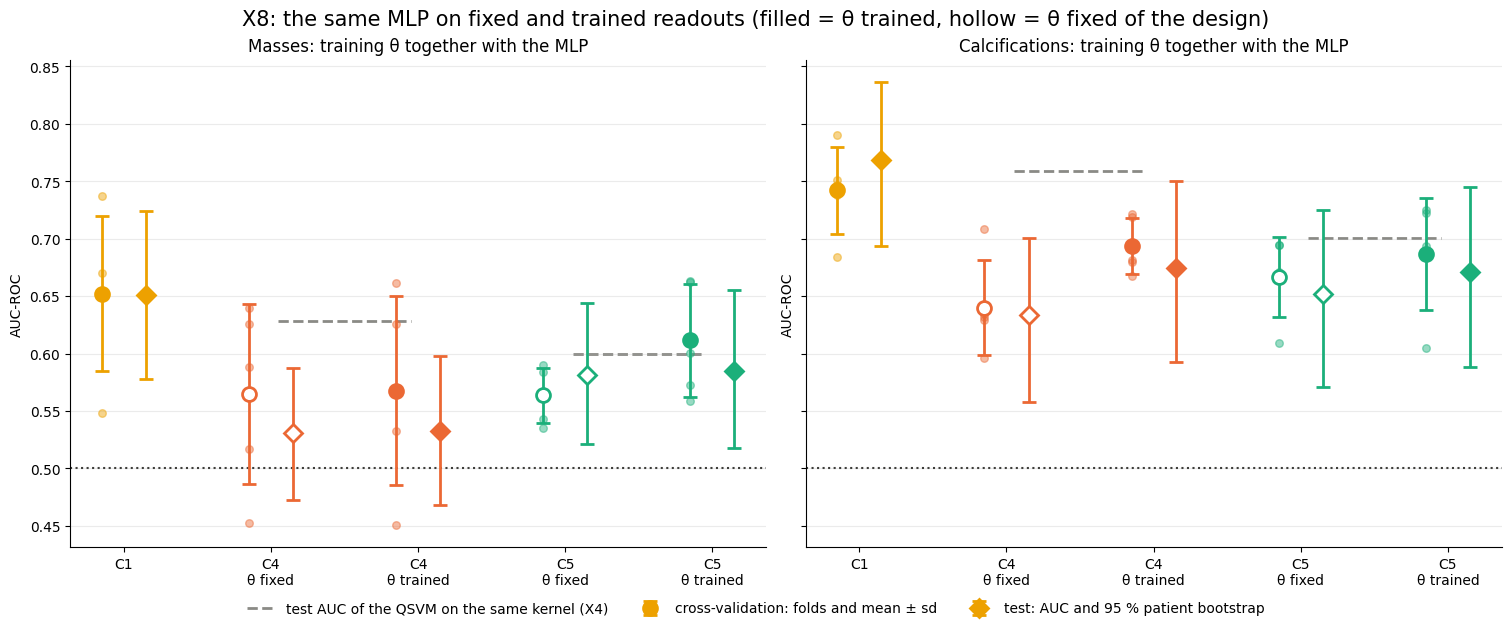

In [8]:
models = [('C1', 'C1', None), ('C4 theta fixed', 'C4', 'fixed'), ('C4 theta trained', 'C4', 'trained'),
          ('C5 theta fixed', 'C5', 'fixed'), ('C5 theta trained', 'C5', 'trained')]
fig, axes = plt.subplots(1, 2, figsize=(15, 6.2), layout='constrained', sharey=True)
for ax, ft in zip(axes, FINDINGS):
    te = test[test.finding_type == ft].set_index('model')
    for i, (name, cond, kind) in enumerate(models):
        if kind == 'trained':
            a = cv[(cv.finding_type == ft) & (cv.condition == cond) & (cv.config == 'main')].auc
        else:
            a = main7[(main7.finding_type == ft) & (main7.condition == cond)].auc
        face = 'white' if kind == 'fixed' else COLORS[cond]
        ax.scatter(np.full(len(a), i - 0.15), a, color=COLORS[cond], alpha=0.45, s=30, zorder=2)
        ax.errorbar(i - 0.15, a.mean(), yerr=a.std(), fmt='o', color=COLORS[cond], markerfacecolor=face, markeredgewidth=2,
                    markersize=10, capsize=5, zorder=3, label='cross-validation: folds and mean ± sd' if i == 0 else None)
        ax.errorbar(i + 0.15, te.loc[name, 'auc'], yerr=[[te.loc[name, 'auc'] - te.loc[name, 'auc_ci_low']], [te.loc[name, 'auc_ci_high'] - te.loc[name, 'auc']]],
                    fmt='D', color=COLORS[cond], markerfacecolor=face, markeredgewidth=2, markersize=9, capsize=5, zorder=3,
                    label='test: AUC and 95 % patient bootstrap' if i == 0 else None)
    for q, x0 in [('C4', 1.5), ('C5', 3.5)]:
        v = x4_test[(x4_test.finding_type == ft) & (x4_test.model == f'QSVM {q}, c = 1')].auc.iloc[0]
        ax.hlines(v, x0 - 0.45, x0 + 0.45, color=MUTED, ls='--', lw=2, zorder=1, label='test AUC of the QSVM on the same kernel (X4)' if q == 'C4' else None)
    ax.axhline(0.5, color=INK, ls=':', lw=1.5)
    ax.set_xticks(range(len(models)), ['C1', 'C4\nθ fixed', 'C4\nθ trained', 'C5\nθ fixed', 'C5\nθ trained'])
    ax.grid(axis='x', visible=False)
    ax.set(title=f'{TITLES[ft]}: training θ together with the MLP', ylabel='AUC-ROC')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='outside lower center', ncol=3, fontsize=10, frameon=False)
fig.suptitle('X8: the same MLP on fixed and trained readouts (filled = θ trained, hollow = θ fixed of the design)', fontsize=15)
fig.savefig(FIG_DIR / 'X8_trained_theta.png', dpi=180, bbox_inches='tight')
plt.show()

#### **5° Verifications and files**

In [9]:
check('every fit stopped before the epoch limit', cv.epochs.max(), cv.epochs.max() < MAX_EPOCHS)
check('one test model per subset and map', sum(j['fold'] == -1 for j in jobs), sum(j['fold'] == -1 for j in jobs) == 4)
verifications = pd.DataFrame(checks)
cv.to_csv(RESULTS_DIR / 'X8_cv_por_fold.csv', index=False)
test.to_csv(RESULTS_DIR / 'X8_test.csv', index=False)
diffs.to_csv(RESULTS_DIR / 'X8_test_diferencias.csv', index=False)
theta_table.to_csv(RESULTS_DIR / 'X8_theta_entrenado.csv', index=False)
verifications.to_csv(RESULTS_DIR / 'X8_verificaciones.csv', index=False)
display(verifications)
print(f'Checks passed: {int(verifications.passed.sum())}/{len(verifications)}')

,check,value,passed
0,theta seed 42 reproduces the theta of Module 5,0.000000e+00,True
1,mass: C4 through the torch layer equals the em...,4.218847e-15,True
2,mass: C5 through the torch layer equals the em...,6.328271e-15,True
3,calcification: C4 through the torch layer equa...,3.941292e-15,True
4,calcification: C5 through the torch layer equa...,5.773160e-15,True
5,parameter shift and the torch layer give the s...,1.881308e-15,True
6,parameter shift and automatic differentiation ...,1.776357e-15,True
7,theta frozen reproduces the fold AUCs of Modul...,0.000000e+00,True
8,every fit stopped before the epoch limit,8.000000e+01,True
9,one test model per subset and map,4.000000e+00,True


Checks passed: 10/10


#### **6° Consequence**

**1. Training θ helps a little and does not close the gap.**

| Mean CV AUC | θ fixed (Module 7) | θ trained | Sensitivity, three configurations | C1 |
|---|---|---|---|---|
| Masses, C4 | 0.565 | 0.568 | 0.565 – 0.595 | 0.652 |
| Masses, C5 | 0.563 | 0.612 | 0.579 – 0.612 | 0.652 |
| Calcifications, C4 | 0.640 | 0.694 | 0.660 – 0.686 | 0.742 |
| Calcifications, C5 | 0.667 | 0.687 | 0.663 – 0.671 | 0.742 |

| Test AUC (once) | θ fixed | θ trained [95 % CI] | Trained − fixed | Trained − C1 | QSVM on the same kernel (X4) |
|---|---|---|---|---|---|
| Masses, C4 | 0.530 | 0.533 [0.47, 0.60] | +0.003 [−0.06, 0.07] | −0.118 [−0.19, −0.04] | 0.628 |
| Masses, C5 | 0.581 | 0.585 [0.52, 0.66] | +0.004 [−0.05, 0.06] | −0.066 [−0.12, −0.02] | 0.599 |
| Calcifications, C4 | 0.633 | 0.674 [0.59, 0.75] | +0.041 [−0.03, 0.10] | −0.094 [−0.15, −0.03] | 0.759 |
| Calcifications, C5 | 0.652 | 0.671 [0.59, 0.75] | +0.020 [−0.04, 0.08] | −0.098 [−0.15, −0.05] | 0.701 |

- **The gain is small and not significant.** Training θ gains 0.00 to 0.05 of AUC in cross-validation and 0.00 to 0.04 in the test, where every interval contains zero.
- **The gap to the classical conditions stays.** All four remain below C1 in the test, with intervals that exclude zero.
- **The QSVM is still ahead.** The trained readouts stay below the QSVM that reads the same kernel without any θ (X4). Twelve trained local observables recover less than the kernel does.
- **θ moves little.** The mean change is 0.13 to 0.39 rad, and the best epoch falls between 4 and 27: the validation loss stops improving early. With about 1,000 lesions per fold, the 24 extra parameters add capacity to fit the training part, not information.

**2. The same gradient, at very different costs.**
- Parameter shift and automatic differentiation give the same Jacobian to within 1.8×10⁻¹⁵.
- Parameter shift costs 5.2 s per lesion, against 1.4 ms for one backward pass: about 3,600 times more.
- Fifty epochs over all the training lesions, for one map, take about 205 h by parameter shift and 3.4 min by automatic differentiation. With six workers sharing the machine, the 89 fits of this notebook took 155 min.
- The first reason of D-014, cost, therefore holds for gradients that a quantum computer can produce, not for the simulator. Architecture A was affordable in simulation through a shortcut that does not exist on hardware, as with H-032.
- The other two reasons of D-014, internal validity and the research question, do not depend on cost.

**For the thesis.**
- The conclusion of Module 7 holds when θ is trained. The loss of C4 and C5 is explained neither by the draw of θ (X7) nor by leaving θ untrained (X8): reading 12 local expectation values loses information that the classical conditions and the kernel keep.
- The test split was used once per subset and map, only for the main configuration fixed before any result.